# Bayesian A/B Testing: Beta-Binomial, Expected Loss, Decisions

**What you'll learn**

- Beta-Binomial conjugacy as a closed-form posterior engine: pseudo-count priors
  (uniform, Jeffreys, history-informed), posteriors you can watch sharpen day by day, and
  the prior sensitivity analysis a reviewer should demand.
- Turning two posteriors into decision quantities by Monte Carlo: $P(p_B > p_A)$,
  credible intervals for absolute and relative lift — with an exact-integral cross-check
  on the simulation.
- The decision-theoretic layer most dashboards hide: **expected loss** (posterior regret),
  the *ship-when-expected-loss-below-$\varepsilon$* stopping rule, and — by simulating
  thousands of repeated experiments — its true frequentist operating characteristics:
  it bounds *regret*, not type-I error.
- **ROPE** (region of practical equivalence): how to conclude "no meaningful difference",
  something a significance test can never give you.
- A two-part (conversion × spend) posterior for zero-inflated revenue using the Bayesian
  bootstrap, decomposed into conversion, AOV, and revenue-per-user readouts.
- An honest frequentist-vs-Bayesian comparison: where the numbers coincide, where the
  guarantees differ, and what a wrong prior does to a credible interval's coverage.

**Why it matters in interviews**

- "Explain $P(B>A)=97\%$ to a PM — is that the same as $p=0.03$?" is a staple
  experimentation question at product companies. Strong answers contrast the *questions
  each number answers*, not just the vocabulary.
- Commercial Bayesian A/B platforms (VWO, legacy Google Optimize, many in-house tools)
  run on exactly the machinery in this notebook; a senior candidate is expected to know
  what the "expected loss" number is and what guarantee it does — and does not — provide.
- "How do you pick a prior defensibly?" and "can Bayesians peek?" probe whether you have
  thought past the marketing.
- ROPE / equivalence comes up whenever a team wants to ship a cost-saving change that
  "shouldn't hurt" the primary metric.

We simulate everything so ground truth is known and every claim can be checked. The
frequentist design/analysis pipeline for the same kind of test lives in
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb);
sequential *frequentist* monitoring is
[../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb).
Here the model is conjugate so we never need MCMC — the full Bayesian workflow with
samplers is [02_pymc_workflow.ipynb](./02_pymc_workflow.ipynb), and priors *learned from
many experiments at once* are [03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import betaln

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)


def beta_moments(a, b):
    """Mean and variance of Beta(a, b). Works elementwise on arrays."""
    mean = a / (a + b)
    var = a * b / ((a + b) ** 2 * (a + b + 1.0))
    return mean, var

## 1. The experiment: one dataset, two philosophies

A subscription product tests a rebuilt pricing page. Arm A is the current page, arm B the
redesign. Primary metric: **trial-signup conversion** among users who land on the page.
The planned horizon is 40,000 users per arm over 14 days (a normal two-week test at this
traffic). Randomization hygiene — hash-based assignment, SRM checks — is assumed clean;
that pipeline is
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)'s
topic.

Because we simulate, we know the truth the analyst does not:

- conversion: $p_A = 4.8\%$, $p_B = 5.1\%$ — a true lift of **+0.3pp** (+6.25% relative);
- spend among converters (first-month plan value): lognormal, mean **\$77.48** under A and
  **\$74.44** under B — the redesign nudges users toward cheaper plans (−3.9% AOV). Money
  returns in Section 8.

One draw of the full experiment, plus the standard frequentist readout for reference:

In [2]:
TRUE_P = {"A": 0.048, "B": 0.051}         # true conversion rates
SPEND_MU = {"A": 3.85, "B": 3.81}         # lognormal params for spend | converted
SPEND_SIGMA = 1.0
N_MAX = 40_000                            # planned users per arm
N_DAYS = 14

conv_A = rng.binomial(1, TRUE_P["A"], N_MAX)   # per-user 0/1 outcomes, in arrival order
conv_B = rng.binomial(1, TRUE_P["B"], N_MAX)
spend_A = np.round(rng.lognormal(SPEND_MU["A"], SPEND_SIGMA, conv_A.sum()), 2)
spend_B = np.round(rng.lognormal(SPEND_MU["B"], SPEND_SIGMA, conv_B.sum()), 2)

xA, xB = int(conv_A.sum()), int(conv_B.sum())
summary = pd.DataFrame({
    "users": [N_MAX, N_MAX],
    "conversions": [xA, xB],
    "rate": [xA / N_MAX, xB / N_MAX],
    "true rate": [TRUE_P["A"], TRUE_P["B"]],
}, index=["A", "B"])
print(summary)
print(f"\nobserved difference: {(xB - xA) / N_MAX:+.4%} (truth {TRUE_P['B'] - TRUE_P['A']:+.2%})")

# the readout most orgs would produce: two-proportion z-test at the fixed horizon
p_pool = (xA + xB) / (2 * N_MAX)
z = ((xB - xA) / N_MAX) / np.sqrt(2 * p_pool * (1 - p_pool) / N_MAX)
print(f"two-proportion z = {z:.3f}, two-sided p = {2 * stats.norm.sf(abs(z)):.4f} "
      f"(one-sided p = {stats.norm.sf(z):.4f})")

   users  conversions    rate  true rate
A  40000         1930  0.0483      0.048
B  40000         2036  0.0509      0.051

observed difference: +0.2650% (truth +0.30%)
two-proportion z = 1.727, two-sided p = 0.0843 (one-sided p = 0.0421)


The frequentist verdict on this (real, +0.3pp) effect: **p = 0.084, not significant at
$\alpha=0.05$** — the test was powered for a bigger effect and this draw came in slightly
under truth (+0.265pp observed). A p-value near 0.08 is where stakeholder conversations go
to die: "so… is it better or not?" The Bayesian analysis below answers the question the
stakeholder is actually asking — *how likely is B better, by how much, and what does it
cost me to ship it if I'm wrong?* — and we will be equally honest about what it does *not*
guarantee.

## 2. Beta-Binomial conjugacy: posteriors in closed form

For a conversion rate $p$ with $x$ successes in $n$ trials, the Beta prior is conjugate:

$$p \sim \mathrm{Beta}(\alpha_0, \beta_0), \quad x \mid p \sim \mathrm{Bin}(n, p)
\;\;\Rightarrow\;\; p \mid x \sim \mathrm{Beta}(\alpha_0 + x,\; \beta_0 + n - x).$$

The prior acts as **pseudo-counts**: $\alpha_0$ prior conversions and $\beta_0$ prior
non-conversions, $\alpha_0+\beta_0$ pseudo-users in total (the prior's *effective sample
size*, ESS). The posterior mean is a precision-weighted blend of prior mean and observed
rate — which is why priors matter early and wash out late. No MCMC needed anywhere: this
is the closed-form workhorse behind every commercial Bayesian A/B tool.

Watch the posterior sharpen as the experiment accumulates (flat $\mathrm{Beta}(1,1)$
prior; days 1, 3, 7, 14):

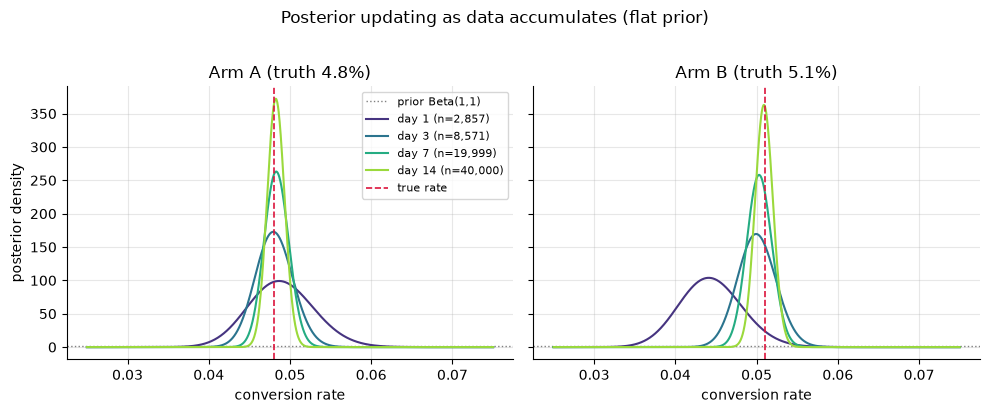

In [3]:
per_day = N_MAX // N_DAYS
n_day = per_day * np.arange(1, N_DAYS + 1)
n_day[-1] = N_MAX                                   # final day tops up to the full horizon
xa_day = np.array([conv_A[:n].sum() for n in n_day])
xb_day = np.array([conv_B[:n].sum() for n in n_day])

grid = np.linspace(0.025, 0.075, 1200)
show_days = [1, 3, 7, 14]
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(show_days)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)
for ax, arm, x_day, truth in [(axes[0], "A", xa_day, TRUE_P["A"]),
                              (axes[1], "B", xb_day, TRUE_P["B"])]:
    ax.axhline(1.0, color="gray", ls=":", lw=1, label="prior Beta(1,1)")
    for c, d in zip(colors, show_days):
        n_d, x_d = n_day[d - 1], x_day[d - 1]
        ax.plot(grid, stats.beta.pdf(grid, 1 + x_d, 1 + n_d - x_d),
                color=c, label=f"day {d} (n={n_d:,})")
    ax.axvline(truth, color="crimson", ls="--", lw=1.2, label="true rate")
    ax.set_title(f"Arm {arm} (truth {truth:.1%})")
    ax.set_xlabel("conversion rate")
axes[0].set_ylabel("posterior density")
axes[0].legend(fontsize=8)
fig.suptitle("Posterior updating as data accumulates (flat prior)", y=1.02)
plt.show()

The flat prior (dotted line at density 1) is invisible at this scale within a day — at
~2,900 users/day, data dominates almost immediately. That observation cuts both ways: it
is why weak-prior Bayesian and frequentist answers coincide at scale, and why the prior
debate mostly matters for *small* experiments.

## 3. Priors: uniform, Jeffreys, informative — and a sensitivity analysis

Four defensible-to-arguable choices:

- **Uniform $\mathrm{Beta}(1,1)$** — "any rate equally likely". ESS 2. The default in most
  tools; effectively lets data speak.
- **Jeffreys $\mathrm{Beta}(\tfrac12,\tfrac12)$** — the invariance-motivated reference
  prior; ESS 1. Practically indistinguishable from uniform here.
- **Informative from history $\mathrm{Beta}(48, 952)$** — last quarter's pricing-page
  conversion ran ~4.8%; this encodes it with ESS 1,000 (2.5% of the planned 40k/arm — a
  sensible cap; in practice you *discount* historical sample size heavily because the past
  is a biased sample of the present: seasonality, mix shift, product changes).
- **Stale history $\mathrm{Beta}(65, 935)$** — the same idea gone wrong: an old 6.5%
  figure from before a pricing change. This is the prior-risk stress test.

The sensitivity analysis reviewers should ask for: the *decision quantity* $P(p_B > p_A)$
under every prior, at several interim sample sizes. We compute it exactly by numerical
integration, $P(p_B > p_A) = \int_0^1 f_B(x)\, F_A(x)\, dx$ (for each candidate value of
$p_B$, the chance $p_A$ sits below it). A closed-form sum also exists — Exercise 2.

In [4]:
PRIORS = {
    "uniform Beta(1,1)": (1.0, 1.0),
    "Jeffreys Beta(.5,.5)": (0.5, 0.5),
    "history Beta(48,952)": (48.0, 952.0),
    "stale Beta(65,935)": (65.0, 935.0),
}

P_GRID = np.linspace(0.0, 0.2, 40_001)   # covers all posterior mass for rates in this range


def prob_B_beats_A(a_A, b_A, a_B, b_B, grid=P_GRID):
    """Exact P(p_B > p_A) for independent Beta posteriors, by numerical integration."""
    return np.trapezoid(stats.beta.pdf(grid, a_B, b_B) * stats.beta.cdf(grid, a_A, b_A), grid)


rows = []
for n_look in [500, 2000, 10_000, 40_000]:
    x_a, x_b = conv_A[:n_look].sum(), conv_B[:n_look].sum()
    for name, (a0, b0) in PRIORS.items():
        a_A, b_A = a0 + x_a, b0 + n_look - x_a
        a_B, b_B = a0 + x_b, b0 + n_look - x_b
        rows.append({"n/arm": n_look, "prior": name,
                     "post mean A": a_A / (a_A + b_A),
                     "post mean B": a_B / (a_B + b_B),
                     "P(B>A)": prob_B_beats_A(a_A, b_A, a_B, b_B)})
sens = pd.DataFrame(rows)

print("P(B > A) by prior and interim sample size:")
print(sens.pivot(index="n/arm", columns="prior", values="P(B>A)")[list(PRIORS)].round(3))
print("\nposterior mean of p_B:")
print(sens.pivot(index="n/arm", columns="prior", values="post mean B")[list(PRIORS)].round(4))

P(B > A) by prior and interim sample size:
prior  uniform Beta(1,1)  Jeffreys Beta(.5,.5)  history Beta(48,952)  stale Beta(65,935)
n/arm                                                                                   
500                0.433                 0.432                 0.464               0.468
2000               0.168                 0.168                 0.215               0.228
10000              0.688                 0.688                 0.680               0.678
40000              0.958                 0.958                 0.956               0.955

posterior mean of p_B:
prior  uniform Beta(1,1)  Jeffreys Beta(.5,.5)  history Beta(48,952)  stale Beta(65,935)
n/arm                                                                                   
500               0.0359                0.0349                0.0433              0.0547
2000              0.0450                0.0447                0.0457              0.0513
10000             0.0500                0.0

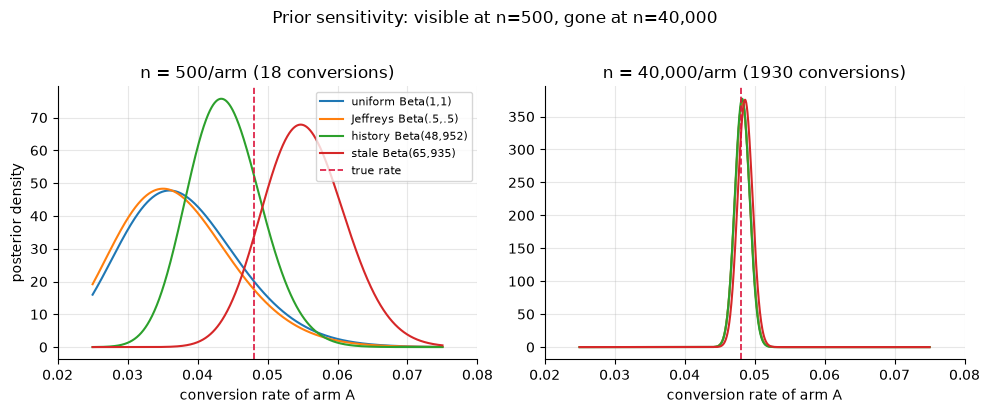

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
for ax, n_look in zip(axes, [500, 40_000]):
    x_a = conv_A[:n_look].sum()
    for name, (a0, b0) in PRIORS.items():
        ax.plot(grid, stats.beta.pdf(grid, a0 + x_a, b0 + n_look - x_a), label=name)
    ax.axvline(TRUE_P["A"], color="crimson", ls="--", lw=1.2, label="true rate")
    ax.set_title(f"n = {n_look:,}/arm ({x_a} conversions)")
    ax.set_xlabel("conversion rate of arm A")
    ax.set_xlim(0.02, 0.08)
axes[0].set_ylabel("posterior density")
axes[0].legend(fontsize=8)
fig.suptitle("Prior sensitivity: visible at n=500, gone at n=40,000", y=1.02)
plt.show()

Three senior-level readings of that table:

- **Early looks are noise.** At 2,000/arm this experiment showed B *losing* —
  $P(B>A) \approx 0.17$ under the flat prior — despite B being truly better. Any rule that
  reacts to early posteriors must price this in (Sections 5–6 do).
- **Priors wash out at the decision.** By 40,000/arm all four priors land within 0.003
  of each other ($P(B>A) \approx 0.955$–$0.958$). Even the deliberately wrong stale prior
  barely moves the answer, because 40k real users swamp 1,000 pseudo-users.
- **Identical priors on both arms mostly cancel in the comparison.** At n=500 the stale
  prior drags *both* posterior means toward 5.5%, yet $P(B>A)$ moves only a few points
  (0.43 → 0.47). Where a shared wrong prior really bites is *absolute* readouts (Section 9
  shows its credible intervals covering the truth only ~75% of the time) and asymmetric
  cases — e.g. a new arm with no history priored from the control's past.

From here on we use the flat prior — at this n it is decision-equivalent to the
alternatives, and it makes the frequentist comparisons cleanest.

## 4. The posterior of the difference: Monte Carlo on two posteriors

The absolute difference $\delta = p_B - p_A$ and relative lift $p_B/p_A - 1$ have no
standard closed-form posterior, and nobody cares: draw from the two Beta posteriors and
push the draws through whatever function you like. This "simulate from the posterior"
move is the whole trick behind Bayesian readouts — it generalizes instantly to lifts,
ratios, revenue (Section 8), or `max(arms)` in multi-way tests.

In [6]:
a_post_A, b_post_A = 1.0 + xA, 1.0 + N_MAX - xA      # flat-prior posteriors
a_post_B, b_post_B = 1.0 + xB, 1.0 + N_MAX - xB

N_MC = 500_000
pA_s = rng.beta(a_post_A, b_post_A, N_MC)
pB_s = rng.beta(a_post_B, b_post_B, N_MC)
delta_s = pB_s - pA_s
lift_s = pB_s / pA_s - 1.0

p_sup_mc = (delta_s > 0).mean()
p_sup_exact = prob_B_beats_A(a_post_A, b_post_A, a_post_B, b_post_B)
ci_delta = np.percentile(delta_s, [2.5, 97.5])
ci_lift = np.percentile(lift_s, [2.5, 97.5])

print(f"P(B > A):  Monte Carlo {p_sup_mc:.4f}   exact integral {p_sup_exact:.4f}   "
      f"(MC se ~ {np.sqrt(p_sup_exact * (1 - p_sup_exact) / N_MC):.4f})")
print(f"delta = p_B - p_A: posterior mean {delta_s.mean() * 100:+.3f}pp, "
      f"95% CI [{ci_delta[0] * 100:+.3f}pp, {ci_delta[1] * 100:+.3f}pp]")
print(f"relative lift:     posterior mean {lift_s.mean():+.2%}, "
      f"95% CI [{ci_lift[0]:+.2%}, {ci_lift[1]:+.2%}]")
print(f"(truth: delta {0.3:+.1f}pp, lift {TRUE_P['B'] / TRUE_P['A'] - 1:+.2%})")

P(B > A):  Monte Carlo 0.9575   exact integral 0.9579   (MC se ~ 0.0003)
delta = p_B - p_A: posterior mean +0.265pp, 95% CI [-0.037pp, +0.566pp]
relative lift:     posterior mean +5.55%, 95% CI [-0.74%, +12.09%]
(truth: delta +0.3pp, lift +6.25%)


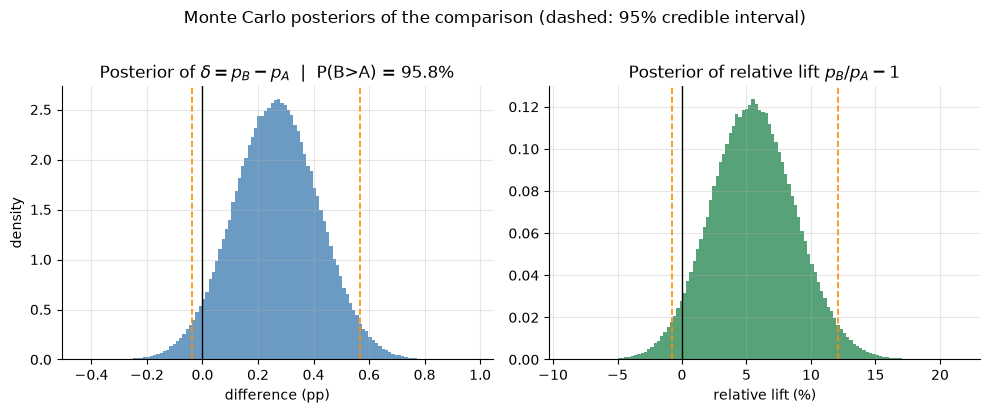

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
axes[0].hist(delta_s * 100, bins=120, density=True, color="steelblue", alpha=0.8)
axes[0].axvline(0, color="black", lw=1)
for q in ci_delta:
    axes[0].axvline(q * 100, color="darkorange", ls="--", lw=1.2)
axes[0].set_title(f"Posterior of $\\delta = p_B - p_A$  |  P(B>A) = {p_sup_mc:.1%}")
axes[0].set_xlabel("difference (pp)")
axes[0].set_ylabel("density")

axes[1].hist(lift_s * 100, bins=120, density=True, color="seagreen", alpha=0.8)
axes[1].axvline(0, color="black", lw=1)
for q in ci_lift:
    axes[1].axvline(q * 100, color="darkorange", ls="--", lw=1.2)
axes[1].set_title("Posterior of relative lift $p_B/p_A - 1$")
axes[1].set_xlabel("relative lift (%)")
fig.suptitle("Monte Carlo posteriors of the comparison (dashed: 95% credible interval)", y=1.02)
plt.show()

Same data as the p = 0.084 z-test, but now the statements are the ones stakeholders
actually want: **there is a ~96% probability B is better; the lift is most likely around
+5%, and values from roughly −1% to +12% are credible.** Note the near-coincidence with
frequentist numbers: the one-sided p-value was 0.042 and $1 - P(B>A) = 0.042$ — with flat
priors and large n these are close to the same number wearing different philosophies
(more in Section 9).

## 5. Expected loss: a decision rule, not a significance test

$P(B>A) = 96\%$ still isn't a decision, because it says nothing about *magnitude*. The
decision-theoretic quantity — the one VWO-style platforms print as "potential loss" — is
the **expected loss** of shipping each arm, under the posterior:

$$\mathcal{L}(\text{ship B}) = E\left[\max(p_A - p_B,\, 0)\right], \qquad
  \mathcal{L}(\text{ship A}) = E\left[\max(p_B - p_A,\, 0)\right].$$

In words: *the conversion you expect to give up by this choice, counting only the worlds
where the choice is wrong.* It blends probability and magnitude: being probably-wrong by a
hair can cost less than being rarely-wrong by a lot. The two losses always differ by the
posterior mean of $\delta$.

**The rule** (Stucchio's formulation, used industry-wide): pick a *threshold of caring*
$\varepsilon$ — the conversion loss so small the business is indifferent — and **stop the
test once $\min(\mathcal{L}_A, \mathcal{L}_B) < \varepsilon$, shipping the arm with the
smaller loss.** We set $\varepsilon = 0.04$pp — under 1% of the 4.8% baseline.

Computation: from the MC draws it is one line. We also verify a closed form built on the
normal approximation $\delta \mid \text{data} \approx N(m, s^2)$, for which
$E[(-\delta)^+] = s\,\varphi(m/s) - m\,\Phi(-m/s)$ — we need it later to evaluate the rule
inside 10,000 simulated experiments where per-experiment MC would be wasteful.

In [8]:
EPS = 4e-4   # threshold of caring: 0.04pp of absolute conversion


def expected_losses_normal(m, s):
    """(loss of shipping A, loss of shipping B) for delta ~ N(m, s^2), elementwise."""
    z = m / s
    loss_B = s * stats.norm.pdf(z) - m * stats.norm.cdf(-z)   # E[(-delta)^+]
    return loss_B + m, loss_B                                  # identity: L_A - L_B = m


loss_ship_B_mc = np.maximum(pA_s - pB_s, 0).mean()
loss_ship_A_mc = np.maximum(pB_s - pA_s, 0).mean()

mean_A, var_A = beta_moments(a_post_A, b_post_A)
mean_B, var_B = beta_moments(a_post_B, b_post_B)
loss_A_norm, loss_B_norm = expected_losses_normal(mean_B - mean_A, np.sqrt(var_A + var_B))

print(f"expected loss if we ship B: {loss_ship_B_mc * 100:.4f}pp   "
      f"(normal approx {loss_B_norm * 100:.4f}pp)")
print(f"expected loss if we ship A: {loss_ship_A_mc * 100:.4f}pp   "
      f"(normal approx {loss_A_norm * 100:.4f}pp)")
print(f"epsilon = {EPS * 100:.2f}pp  ->  decision: "
      f"{'SHIP B' if min(loss_ship_A_mc, loss_ship_B_mc) == loss_ship_B_mc else 'SHIP A'} "
      f"(min loss {min(loss_ship_A_mc, loss_ship_B_mc) * 100:.4f}pp < eps)")

expected loss if we ship B: 0.0027pp   (normal approx 0.0026pp)
expected loss if we ship A: 0.2678pp   (normal approx 0.2676pp)
epsilon = 0.04pp  ->  decision: SHIP B (min loss 0.0027pp < eps)


Shipping B risks an expected **0.003pp** of conversion; sticking with A risks **0.27pp**
— a ~100× asymmetry that the p = 0.084 readout completely hides. The normal approximation
agrees with MC to the displayed precision, so we can trust it as the fast engine.

In practice this rule runs *as the test accumulates* — that is its selling point ("stop
early when the decision is cheap"). Here is the full monitoring trajectory of this
experiment, evaluated daily:

 day  n/arm  loss ship A (pp)  loss ship B (pp)  P(B>A)
   1   2857            0.0653            0.5200  0.2075
   2   5714            0.3911            0.0412  0.8111
   3   8571            0.2538            0.0555  0.7261
   4  11428            0.1183            0.1095  0.5122
   5  14285            0.1235            0.0815  0.5658
   6  17142            0.1395            0.0578  0.6369
   7  19999            0.2208            0.0208  0.8221
   8  22856            0.1593            0.0324  0.7353
   9  25713            0.1935            0.0185  0.8208
  10  28570            0.1881            0.0166  0.8286
  11  31427            0.1889            0.0139  0.8454
  12  34284            0.1797            0.0134  0.8438
  13  37141            0.2981            0.0019  0.9689
  14  40000            0.2676            0.0026  0.9578

first day with min expected loss < eps: day 7 (19,999 users/arm) -> ship B


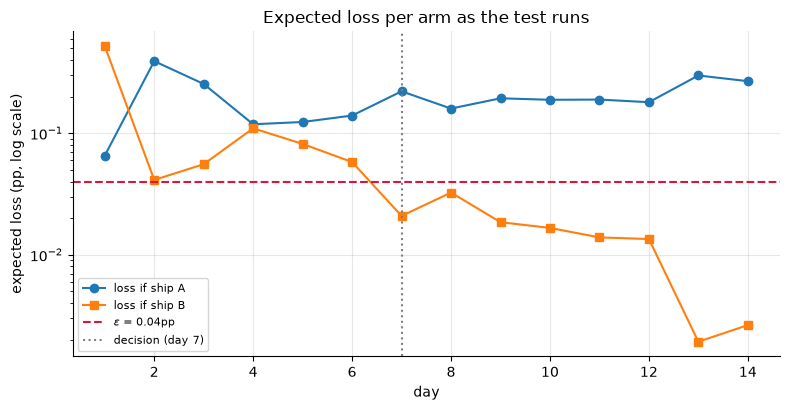

In [9]:
a_A_d, b_A_d = 1.0 + xa_day, 1.0 + n_day - xa_day
a_B_d, b_B_d = 1.0 + xb_day, 1.0 + n_day - xb_day
mA_d, vA_d = beta_moments(a_A_d, b_A_d)
mB_d, vB_d = beta_moments(a_B_d, b_B_d)
m_d, s_d = mB_d - mA_d, np.sqrt(vA_d + vB_d)
lossA_d, lossB_d = expected_losses_normal(m_d, s_d)

traj = pd.DataFrame({"day": np.arange(1, N_DAYS + 1), "n/arm": n_day,
                     "loss ship A (pp)": lossA_d * 100, "loss ship B (pp)": lossB_d * 100,
                     "P(B>A)": stats.norm.cdf(m_d / s_d)})
print(traj.round(4).to_string(index=False))
stop_day = int(traj["day"][np.minimum(lossA_d, lossB_d) < EPS].iloc[0])
print(f"\nfirst day with min expected loss < eps: day {stop_day} "
      f"({n_day[stop_day - 1]:,} users/arm) -> ship B")

fig, ax = plt.subplots()
ax.semilogy(traj["day"], traj["loss ship A (pp)"], "o-", label="loss if ship A")
ax.semilogy(traj["day"], traj["loss ship B (pp)"], "s-", label="loss if ship B")
ax.axhline(EPS * 100, color="crimson", ls="--", label=f"$\\varepsilon$ = {EPS * 100:.2f}pp")
ax.axvline(stop_day, color="gray", ls=":", label=f"decision (day {stop_day})")
ax.set_xlabel("day")
ax.set_ylabel("expected loss (pp, log scale)")
ax.set_title("Expected loss per arm as the test runs")
ax.legend(fontsize=8)
plt.show()

The trajectory is honest about how wiggly monitoring really is: on day 1 B looked
*worse*; on day 2 a noisy spike in B's favor took its loss to 0.041pp — a hair above
$\varepsilon$; the threshold is genuinely crossed on **day 7 at ~20,000 users/arm**, half
the planned traffic. Which raises the question every senior candidate must be able to
answer: *what are the error properties of a rule that stares at the posterior every day?*

## 6. Operating characteristics of "ship when expected loss < ε"

A Bayesian decision rule is still a *procedure*, and nothing stops us from evaluating it
exactly the way a frequentist would: fix a true effect, run the procedure thousands of
times, count what it does. We simulate the full monitoring policy — check after every
2,000 users/arm, up to 40,000 (20 looks); at the horizon, ship the lower-loss arm — for
five true effects, 2,000 experiments each. We track the **realized regret**: the true
conversion given up when the rule ships the truly-worse arm.

In [10]:
def run_decision_sims(delta_true, seed, n_sims=2000, p_base=0.048, batch=2000,
                      n_checks=20, eps=EPS, a0=1.0, b0=1.0):
    """Simulate the eps-loss monitoring rule on `n_sims` experiments; fully vectorized."""
    r = np.random.default_rng(seed)
    n_cum = batch * np.arange(1, n_checks + 1)
    x_a = r.binomial(batch, p_base, (n_sims, n_checks)).cumsum(axis=1)
    x_b = r.binomial(batch, p_base + delta_true, (n_sims, n_checks)).cumsum(axis=1)
    mA, vA = beta_moments(a0 + x_a, b0 + n_cum - x_a)
    mB, vB = beta_moments(a0 + x_b, b0 + n_cum - x_b)
    m, s = mB - mA, np.sqrt(vA + vB)
    loss_A, loss_B = expected_losses_normal(m, s)
    hit = np.minimum(loss_A, loss_B) < eps
    hit[:, -1] = True                                   # forced call at the horizon
    t_stop = hit.argmax(axis=1)                         # first look that triggers
    idx = np.arange(n_sims)
    ship_B = loss_B[idx, t_stop] <= loss_A[idx, t_stop]
    regret = np.where(ship_B, max(-delta_true, 0), max(delta_true, 0))
    # fixed-horizon frequentist benchmark on the same data: ship B iff z > 1.96 at n_max
    n_f = n_cum[-1]
    pp_ = (x_a[:, -1] + x_b[:, -1]) / (2 * n_f)
    z_f = (x_b[:, -1] - x_a[:, -1]) / n_f / np.sqrt(2 * pp_ * (1 - pp_) / n_f)
    return dict(ship_B=ship_B, n_stop=n_cum[t_stop], regret=regret,
                stopped_early=t_stop < n_checks - 1,
                freq_ship_B=z_f > stats.norm.ppf(0.975),
                prob_sup=stats.norm.cdf(m / s))         # P(B>A) path, reused in Pitfall 2


oc_rows, oc_results = [], {}
for i, d in enumerate([-0.003, -0.001, 0.0, 0.001, 0.003]):
    res = run_decision_sims(d, seed=101 + i)
    oc_results[d] = res
    oc_rows.append({"true delta (pp)": d * 100,
                    "Bayes ships B (%)": 100 * res["ship_B"].mean(),
                    "stopped early (%)": 100 * res["stopped_early"].mean(),
                    "mean n/arm at stop": res["n_stop"].mean(),
                    "mean regret (pp)": 100 * res["regret"].mean(),
                    "fixed-n z-test ships B (%)": 100 * res["freq_ship_B"].mean()})
oc = pd.DataFrame(oc_rows)
print(oc.round(3).to_string(index=False))
print(f"\nepsilon = {EPS * 100:.2f}pp; horizon 40,000/arm; 20 looks; 2,000 sims/scenario")

 true delta (pp)  Bayes ships B (%)  stopped early (%)  mean n/arm at stop  mean regret (pp)  fixed-n z-test ships B (%)
            -0.3              13.65              99.90              6775.0             0.041                        0.00
            -0.1              34.70              99.60              8718.0             0.035                        0.60
             0.0              50.10              99.35              8791.0             0.000                        3.00
             0.1              64.90              99.40              8766.0             0.035                        9.65
             0.3              85.35              99.90              7089.0             0.044                       49.25

epsilon = 0.04pp; horizon 40,000/arm; 20 looks; 2,000 sims/scenario


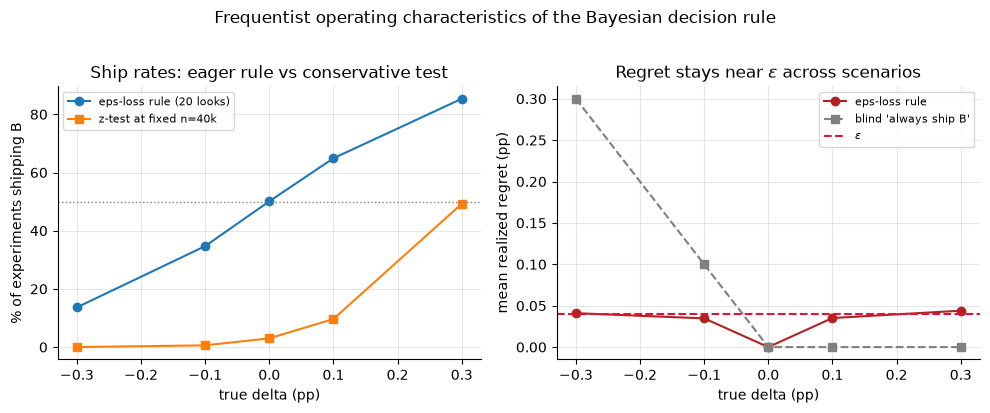

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
dd = oc["true delta (pp)"]
axes[0].plot(dd, oc["Bayes ships B (%)"], "o-", label="eps-loss rule (20 looks)")
axes[0].plot(dd, oc["fixed-n z-test ships B (%)"], "s-", label="z-test at fixed n=40k")
axes[0].axhline(50, color="gray", ls=":", lw=1)
axes[0].set_xlabel("true delta (pp)")
axes[0].set_ylabel("% of experiments shipping B")
axes[0].set_title("Ship rates: eager rule vs conservative test")
axes[0].legend(fontsize=8)

axes[1].plot(dd, oc["mean regret (pp)"], "o-", color="firebrick", label="eps-loss rule")
axes[1].plot(dd, np.maximum(-dd, 0), "s--", color="gray", label="blind 'always ship B'")
axes[1].axhline(EPS * 100, color="crimson", ls="--", label="$\\varepsilon$")
axes[1].set_xlabel("true delta (pp)")
axes[1].set_ylabel("mean realized regret (pp)")
axes[1].set_title("Regret stays near $\\varepsilon$ across scenarios")
axes[1].legend(fontsize=8)
fig.suptitle("Frequentist operating characteristics of the Bayesian decision rule", y=1.02)
plt.show()

This table is the honest heart of the notebook. Read it row by row:

- **Null ($\delta = 0$): the rule ships B ~50% of the time.** By NHST bookkeeping that is
  a 50% "false positive rate" — and it is *by design*. When arms are identical, shipping
  either costs nothing (regret is exactly 0), so the rule happily flips a data-informed
  coin instead of burning 40k users/arm to detect nothing. If a stakeholder will interpret
  "we shipped B" as "B was proven better", this rule will burn you — that's a
  communication contract, not a math problem.
- **B truly worse by 0.1pp / 0.3pp: the rule ships the loser 35% / 14% of the time** —
  numbers that would end a frequentist's career — yet mean regret is 0.035pp / 0.041pp,
  i.e. at the $\varepsilon$ we declared we don't care about. Wrong ships are common but
  cheap; expensive wrongness is rare. Note 0.041pp slightly *exceeds* $\varepsilon$:
  the guarantee is on posterior expected loss at stopping, *averaged over the prior* —
  a fixed-truth slice under continuous monitoring can run a bit over. It is a regret
  bound, not a worst-case contract.
- **Speed: mean stopping time is ~7–9k users/arm, a 4–6× saving** over the fixed-horizon
  design, with >99% of experiments stopping early.
- **The z-test column is the mirror image**: it never ships the −0.3pp loser (0%) but
  catches only ~49% of the genuine +0.3pp winners while always spending the full 40k/arm.
  Neither column dominates — they optimize different objectives (error control vs regret),
  which is the entire frequentist/Bayes decision-rule trade in one table.

The logical endpoint of "optimize regret, not error rates" is to drop fixed allocation
altogether — Thompson sampling, in
[04_bandits_thompson.ipynb](./04_bandits_thompson.ipynb).

## 7. ROPE: concluding "no meaningful difference"

NHST cannot accept a null — absence of evidence is not evidence of absence (the TOST
equivalence-testing workaround is in
[../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb)).
The Bayesian version is direct: declare a **region of practical equivalence** around zero
— differences too small for anyone to act on — and read posterior mass off it. We use
ROPE = ±0.1pp (≈ ±2% relative), which should be set with the same business logic as the
MDE in [../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb).

Kruschke's decision grammar, using the 95% **HDI** (highest-density interval — the
narrowest interval holding 95% of posterior mass; for near-symmetric posteriors it is
almost identical to the equal-tailed interval):

- HDI entirely **inside** ROPE → declare practical equivalence;
- HDI entirely **outside** ROPE → declare a meaningful difference;
- otherwise → undecided; collect more data or fall back on expected loss.

In [12]:
ROPE = (-0.001, 0.001)   # +/- 0.1pp


def hdi(samples, cred=0.95):
    """Highest-density interval from MC samples (narrowest window with `cred` mass)."""
    x = np.sort(samples)
    k = int(np.floor(cred * len(x)))
    j = np.argmin(x[k:] - x[:-k])
    return x[j], x[j + k]


hdi_main = hdi(delta_s)
in_rope_main = ((delta_s > ROPE[0]) & (delta_s < ROPE[1])).mean()
print("Main experiment (40k/arm, true delta +0.3pp):")
print(f"  95% HDI [{hdi_main[0] * 100:+.3f}pp, {hdi_main[1] * 100:+.3f}pp], "
      f"P(delta in ROPE) = {in_rope_main:.1%}  ->  HDI overlaps ROPE: undecided")

# a true A/A comparison at scale: can we ever CONCLUDE equivalence?
N_BIG = 600_000
xA_aa = int(rng.binomial(N_BIG, 0.048))
xB_aa = int(rng.binomial(N_BIG, 0.048))
pA_aa = rng.beta(1 + xA_aa, 1 + N_BIG - xA_aa, N_MC)
pB_aa = rng.beta(1 + xB_aa, 1 + N_BIG - xB_aa, N_MC)
delta_aa = pB_aa - pA_aa
hdi_aa = hdi(delta_aa)
in_rope_aa = ((delta_aa > ROPE[0]) & (delta_aa < ROPE[1])).mean()
print(f"\nA/A comparison at 600,000/arm (true delta = 0):")
print(f"  rates {xA_aa / N_BIG:.4%} vs {xB_aa / N_BIG:.4%}")
print(f"  95% HDI [{hdi_aa[0] * 100:+.3f}pp, {hdi_aa[1] * 100:+.3f}pp], "
      f"P(delta in ROPE) = {in_rope_aa:.1%}  ->  HDI inside ROPE: practical equivalence")

Main experiment (40k/arm, true delta +0.3pp):
  95% HDI [-0.036pp, +0.566pp], P(delta in ROPE) = 13.2%  ->  HDI overlaps ROPE: undecided

A/A comparison at 600,000/arm (true delta = 0):
  rates 4.7833% vs 4.7740%
  95% HDI [-0.085pp, +0.067pp], P(delta in ROPE) = 98.8%  ->  HDI inside ROPE: practical equivalence


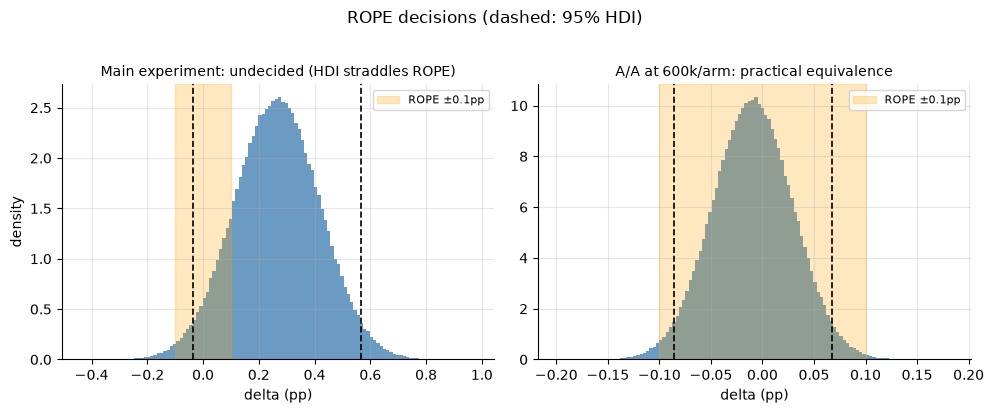

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
for ax, d_s, h, title in [
        (axes[0], delta_s, hdi_main, "Main experiment: undecided (HDI straddles ROPE)"),
        (axes[1], delta_aa, hdi_aa, "A/A at 600k/arm: practical equivalence")]:
    ax.hist(d_s * 100, bins=120, density=True, color="steelblue", alpha=0.8)
    ax.axvspan(ROPE[0] * 100, ROPE[1] * 100, color="orange", alpha=0.25, label="ROPE ±0.1pp")
    for q in h:
        ax.axvline(q * 100, color="black", ls="--", lw=1.2)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("delta (pp)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("density")
fig.suptitle("ROPE decisions (dashed: 95% HDI)", y=1.02)
plt.show()

Note the price tag: even with a *true* zero effect, certifying "no meaningful difference"
against a ±0.1pp ROPE took 600,000 users/arm — equivalence is far more expensive than
superiority because the posterior must fit *inside* a narrow band, not merely exclude a
point (Exercise 3 derives the required n). This is why "the test was flat" after 40k
users must be reported as *undecided at our sensitivity*, not "no difference".

## 8. Revenue: a two-part posterior for zero-inflated money

Revenue per user is ~95% zeros with a heavy lognormal-ish tail — modeling it directly
with a normal likelihood is both wrong and unnecessary. Factor it:

$$\text{revenue/user} = \underbrace{p}_{\text{conversion}} \times
  \underbrace{\mu}_{E[\text{spend} \mid \text{converted}]},$$

and give each factor its own posterior: Beta-Binomial for $p$ (done), and for $\mu$ — to
stay likelihood-free about the awkward spend shape — the **Bayesian bootstrap** (Rubin
1981): posterior draws of the mean are Dirichlet-weighted averages of the observed
spends, the smoothed Bayesian twin of the classical bootstrap from
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb).
(A parametric lognormal/gamma model in PyMC is the other standard route —
[02_pymc_workflow.ipynb](./02_pymc_workflow.ipynb).) Multiplying independent draws of $p$
and $\mu$ gives the posterior of revenue per user, and the whole Section 4–5 toolkit —
$P(B>A)$, credible intervals, expected loss in dollars — applies unchanged.

In [14]:
def bayes_boot_mean(x, n_draws, r):
    """Bayesian-bootstrap posterior draws of E[x]: Dirichlet(1,...,1)-weighted means."""
    w = r.dirichlet(np.ones(len(x)), size=n_draws)
    return w @ x


N_REV = 4000
mu_A_s = bayes_boot_mean(spend_A, N_REV, rng)          # posterior of mean spend | converted
mu_B_s = bayes_boot_mean(spend_B, N_REV, rng)
pA_r = rng.beta(a_post_A, b_post_A, N_REV)             # conversion posteriors, matched draws
pB_r = rng.beta(a_post_B, b_post_B, N_REV)
rpu_A_s, rpu_B_s = pA_r * mu_A_s, pB_r * mu_B_s

decomp = pd.DataFrame({
    "post mean A": [pA_r.mean(), mu_A_s.mean(), rpu_A_s.mean()],
    "post mean B": [pB_r.mean(), mu_B_s.mean(), rpu_B_s.mean()],
    "post mean lift (%)": [100 * (pB_r / pA_r - 1).mean(),
                           100 * (mu_B_s / mu_A_s - 1).mean(),
                           100 * (rpu_B_s / rpu_A_s - 1).mean()],
    "P(B better)": [(pB_r > pA_r).mean(), (mu_B_s > mu_A_s).mean(),
                    (rpu_B_s > rpu_A_s).mean()],
}, index=["conversion", "AOV (spend|conv)", "revenue/user"])
print(decomp.round(4))
print(f"\ntruth: AOV A ${np.exp(SPEND_MU['A'] + 0.5):.2f} vs B ${np.exp(SPEND_MU['B'] + 0.5):.2f} "
      f"(-3.9%); revenue/user A ${TRUE_P['A'] * np.exp(SPEND_MU['A'] + 0.5):.3f} "
      f"vs B ${TRUE_P['B'] * np.exp(SPEND_MU['B'] + 0.5):.3f} (+2.1%)")

d_rpu = rpu_B_s - rpu_A_s
ci_rpu = np.percentile(d_rpu, [2.5, 97.5])
loss_rev_B = np.maximum(-d_rpu, 0).mean()
loss_rev_A = np.maximum(d_rpu, 0).mean()
eps_rev = 0.01 * rpu_A_s.mean()   # threshold of caring: 1% of baseline RPU
print(f"\nrevenue/user difference: mean ${d_rpu.mean():+.3f}, "
      f"95% CI [${ci_rpu[0]:+.3f}, ${ci_rpu[1]:+.3f}]")
print(f"expected loss ship B: ${loss_rev_B:.4f}/user | ship A: ${loss_rev_A:.4f}/user | "
      f"eps_rev = ${eps_rev:.4f}/user")
print(f"at 1M users/month: expected regret of shipping B ~ ${1e6 * loss_rev_B:,.0f}/month "
      f"vs expected upside ~ ${1e6 * d_rpu.mean():,.0f}/month")

                  post mean A  post mean B  post mean lift (%)  P(B better)
conversion             0.0483       0.0509              5.4663       0.9538
AOV (spend|conv)      78.3149      77.5293             -0.9041       0.4090
revenue/user           3.7822       3.9468              4.5118       0.7870

truth: AOV A $77.48 vs B $74.44 (-3.9%); revenue/user A $3.719 vs B $3.796 (+2.1%)

revenue/user difference: mean $+0.165, 95% CI [$-0.253, $+0.588]
expected loss ship B: $0.0255/user | ship A: $0.1901/user | eps_rev = $0.0378/user
at 1M users/month: expected regret of shipping B ~ $25,484/month vs expected upside ~ $164,647/month


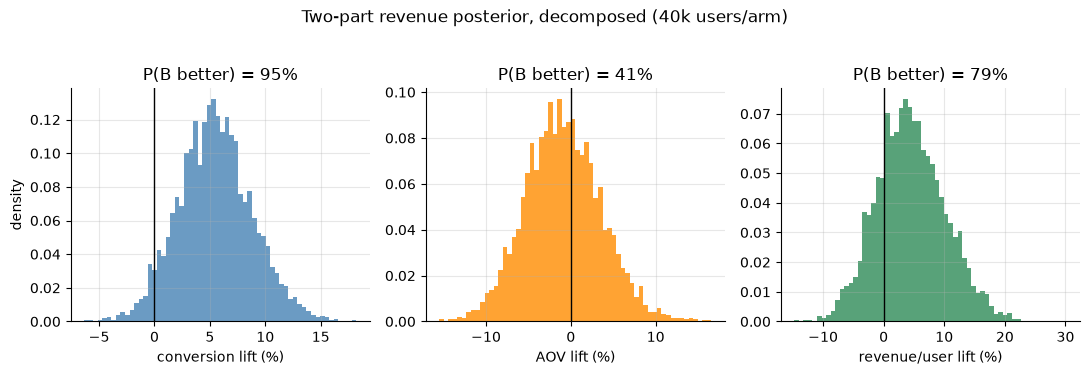

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=False)
panels = [((pB_r / pA_r - 1) * 100, "conversion lift (%)", "steelblue"),
          ((mu_B_s / mu_A_s - 1) * 100, "AOV lift (%)", "darkorange"),
          ((rpu_B_s / rpu_A_s - 1) * 100, "revenue/user lift (%)", "seagreen")]
for ax, (samples, label, color) in zip(axes, panels):
    ax.hist(samples, bins=60, density=True, color=color, alpha=0.8)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel(label)
    ax.set_title(f"P(B better) = {(samples > 0).mean():.0%}")
axes[0].set_ylabel("density")
fig.suptitle("Two-part revenue posterior, decomposed (40k users/arm)", y=1.03)
plt.show()

The decomposition tells the product story the way a strong DS would tell it: **B lifts
conversion (~95% probable) while AOV is a wash in the data** — the posterior can't see
the true −3.9% AOV drop because ~2,000 converters of heavy-tailed spend carry far less
information than 40,000 Bernoullis. Net revenue/user favors B at only ~79% probability
with a dollar CI spanning zero, and the posterior-mean upside (≈ +\$0.16/user) overstates
the simulation truth (+\$0.08) — a reminder that noisy metrics produce optimistic point
estimates conditional on looking good. The expected-loss framing still supports shipping
(loss ≈ \$0.03/user < $\varepsilon_{rev}$), but honesty requires reporting *conversion
won, revenue plausibly-but-not-provably neutral-to-positive* — and if AOV is a guardrail,
running the longer, revenue-powered test. Variance-reduction for exactly this problem:
[../02_ab_testing/03_variance_reduction_cuped.ipynb](../02_ab_testing/03_variance_reduction_cuped.ipynb).

## 9. Frequentist vs Bayesian: the honest comparison

| | Frequentist NHST | Bayesian (this notebook) |
|---|---|---|
| Question answered | "How surprising is this data if nothing is going on?" | "Given data + prior, what should I believe about the effect?" |
| Primary outputs | p-value, CI, point estimate | full posterior: $P(B>A)$, credible intervals, expected loss |
| Guarantee | type-I error $\le \alpha$, known power — *if* the fixed design is respected | expected regret at stopping $\lesssim \varepsilon$, averaged over the prior; **no error-rate control** |
| Peeking | invalidates $\alpha$ unless you buy sequential machinery ([../02_ab_testing/04](../02_ab_testing/04_peeking_sequential.ipynb)) | posterior stays a valid *belief* at every look, but error rates still inflate (Pitfall 2); the loss rule *budgets* for monitoring rather than being immune to it |
| Small samples | underpowered, wide CIs | informative priors genuinely help — if defensible |
| "No difference" | only via extra machinery (TOST) | native, via ROPE |
| Costs | correction rituals (multiplicity, sequential); chronic misinterpretation | prior justification and sensitivity analyses; stakeholder education about regret |
| Communication | statements nobody wants, routinely misread | statements PMs already think they're getting — which is exactly why sloppy Bayes is dangerous |

**The misconception worth naming**: *"credible intervals are what people wish confidence
intervals were."* True as far as interpretation goes — "95% probability the lift is in
here" is a statement about *this* interval, which no CI licenses
(see the coverage machinery in
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)).
But the upgrade is not free: the probability is conditional on the prior. Three facts,
demonstrated below:

1. With flat priors and decent n, credible and confidence intervals **numerically
   coincide** — the philosophical upgrade costs nothing but also changes nothing.
2. A *correct* informative prior gives narrower intervals with *better*-than-nominal
   frequentist coverage — the legitimate free lunch history can buy you.
3. A *wrong* informative prior produces confidently wrong intervals — coverage collapses,
   and no amount of interpretation-upgrading fixes miscalibrated beliefs.

In [16]:
def wilson_ci(x, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2)
    ph = x / n
    den = 1 + z ** 2 / n
    center = (ph + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(ph * (1 - ph) / n + z ** 2 / (4 * n ** 2)) / den
    return center - half, center + half


cred = stats.beta.ppf([0.025, 0.975], a_post_A, b_post_A)
wils = wilson_ci(xA, N_MAX)
print("Arm A, n=40,000 — the numeric coincidence:")
print(f"  95% credible (flat prior): [{cred[0]:.5f}, {cred[1]:.5f}]")
print(f"  95% Wilson confidence:     [{wils[0]:.5f}, {wils[1]:.5f}]")


def credible_coverage(p_true, n, a0, b0, reps, r):
    """Frequentist coverage of the equal-tailed 95% posterior interval."""
    x = r.binomial(n, p_true, reps)
    lo = stats.beta.ppf(0.025, a0 + x, b0 + n - x)
    hi = stats.beta.ppf(0.975, a0 + x, b0 + n - x)
    return ((lo <= p_true) & (p_true <= hi)).mean()


def wilson_coverage(p_true, n, reps, r):
    x = r.binomial(n, p_true, reps)
    lo, hi = wilson_ci(x, n)
    return ((lo <= p_true) & (p_true <= hi)).mean()


REPS, N_COV, P_TRUE = 20_000, 2000, 0.048
cov = pd.DataFrame({
    "interval": ["credible, flat Beta(1,1)", "credible, Jeffreys",
                 "credible, Beta(48,952) — prior mean = truth",
                 "credible, Beta(65,935) — prior mean 6.5%, truth 4.8%",
                 "Wilson CI (frequentist)"],
    "coverage of true p": [
        credible_coverage(P_TRUE, N_COV, 1, 1, REPS, rng),
        credible_coverage(P_TRUE, N_COV, 0.5, 0.5, REPS, rng),
        credible_coverage(P_TRUE, N_COV, 48, 952, REPS, rng),
        credible_coverage(P_TRUE, N_COV, 65, 935, REPS, rng),
        wilson_coverage(P_TRUE, N_COV, REPS, rng),
    ],
})
print(f"\nFrequentist coverage of 95% intervals (n={N_COV:,}, true p={P_TRUE:.1%}, "
      f"{REPS:,} replications):")
print(cov.to_string(index=False))

Arm A, n=40,000 — the numeric coincidence:
  95% credible (flat prior): [0.04619, 0.05039]
  95% Wilson confidence:     [0.04619, 0.05039]

Frequentist coverage of 95% intervals (n=2,000, true p=4.8%, 20,000 replications):
                                            interval  coverage of true p
                            credible, flat Beta(1,1)              0.9453
                                  credible, Jeffreys              0.9556
         credible, Beta(48,952) — prior mean = truth              0.9844
credible, Beta(65,935) — prior mean 6.5%, truth 4.8%              0.7548
                             Wilson CI (frequentist)              0.9462


Exactly as advertised: flat-prior credible intervals behave like CIs (~95% coverage, and
the interval endpoints match Wilson's to about four decimals); the correct informative
prior over-covers at ~98% with narrower intervals; the stale prior covers the truth only
~75% of the time while *claiming* 95% — confidently, narrowly wrong. "Bayesian" is not a
safety property; the prior is a modeling assumption with consequences, and the sensitivity
analysis of Section 3 is the audit.

## 10. Pitfalls

### Pitfall 1: treating P(B>A) as a decision

Probability of superiority is scale-free — it can be identical for a decision that is
obviously safe and one that is reckless. Two experiments, essentially the same headline
probability ($P(B>A)$ of 0.92 vs 0.91):

In [17]:
pitfall1 = []
for label, n_, x_a, x_b in [("startup: n=50/arm", 50, 2, 6),
                            ("platform: n=60,000/arm", 60_000, 2880, 2980)]:
    a_A, b_A = 1.0 + x_a, 1.0 + n_ - x_a
    a_B, b_B = 1.0 + x_b, 1.0 + n_ - x_b
    mA, vA = beta_moments(a_A, b_A)
    mB, vB = beta_moments(a_B, b_B)
    _, l_B = expected_losses_normal(mB - mA, np.sqrt(vA + vB))
    pitfall1.append({"experiment": label, "rate A": x_a / n_, "rate B": x_b / n_,
                     "P(B>A)": prob_B_beats_A(a_A, b_A, a_B, b_B,
                                              grid=np.linspace(0, 0.5, 40_001)),
                     "loss if ship B (pp)": l_B * 100, "x eps": l_B / EPS})
print(pd.DataFrame(pitfall1).round(3).to_string(index=False))

            experiment  rate A  rate B  P(B>A)  loss if ship B (pp)  x eps
     startup: n=50/arm   0.040    0.12    0.92                0.230  5.745
platform: n=60,000/arm   0.048    0.05    0.91                0.005  0.130


Same headline probability; the small experiment's expected loss is **~6× over the
$\varepsilon$ budget** (ship B and you're exposed to a plausible multi-pp downside), while
the large one is at 0.1× (whatever error remains is microscopic). Any dashboard that
surfaces $P(B>A)$ without a loss/magnitude number invites this error — and "we hit 91%!"
with 8 total conversions is exactly how it gets made.

### Pitfall 2: "Bayesian methods are immune to peeking"

The posterior is always a coherent belief given the data so far — that part is true. But
if you *act* on a threshold like "$P(B>A) \ge 95\%$", the frequency with which that
threshold is crossed under the null depends entirely on how often you look. Reusing the
2,000 null experiments from Section 6 (20 looks each):

A/A experiments where P(B>A) > 95%:  at the final look only: 5.2%   at ANY of 20 looks: 22.2%


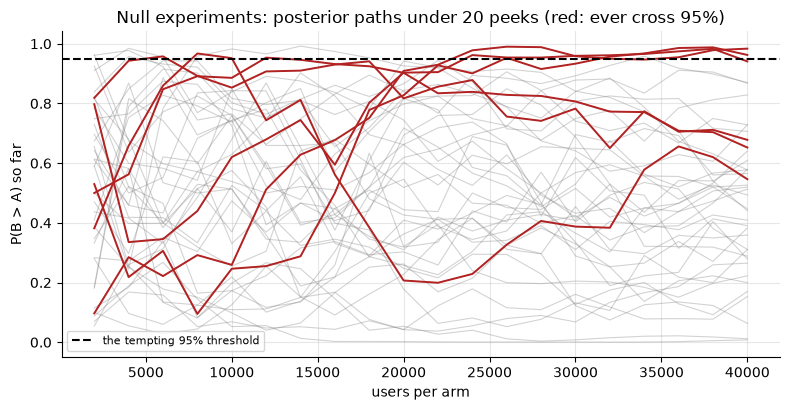

In [18]:
prob_sup_null = oc_results[0.0]["prob_sup"]
ever = (prob_sup_null.max(axis=1) > 0.95).mean()
final = (prob_sup_null[:, -1] > 0.95).mean()
print(f"A/A experiments where P(B>A) > 95%:  at the final look only: {final:.1%}   "
      f"at ANY of 20 looks: {ever:.1%}")

fig, ax = plt.subplots()
crossers = np.where(prob_sup_null.max(axis=1) > 0.95)[0]
look = np.arange(1, prob_sup_null.shape[1] + 1) * 2000
for i in range(40):                                     # a representative handful
    ax.plot(look, prob_sup_null[i], color="gray", alpha=0.35, lw=0.8)
for i in crossers[:6]:
    ax.plot(look, prob_sup_null[i], color="firebrick", lw=1.4)
ax.axhline(0.95, color="black", ls="--", label="the tempting 95% threshold")
ax.set_xlabel("users per arm")
ax.set_ylabel("P(B > A) so far")
ax.set_title("Null experiments: posterior paths under 20 peeks (red: ever cross 95%)")
ax.legend(fontsize=8)
plt.show()

A "stop at 95%" rule certifies a phantom winner in **~22% of A/A tests** — worse than
fourfold the 5.2% you'd naively expect, and it grows with more looks. This is p-hacking
in posterior clothing (the same inflation mechanics as
[../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb)).
What *is* defensible under monitoring: the expected-loss rule — not because its error
rate is controlled (Section 6 showed it isn't) but because the quantity it does control,
regret, is the one it promises. Know which guarantee you're selling.

### Pitfall 3: forgetting what independent flat priors say about the lift

Putting independent $\mathrm{Beta}(1,1)$ priors on $p_A$ and $p_B$ *feels* neutral. Look
at what it implies about $\delta = p_B - p_A$ — the thing you actually have beliefs about:

implied prior on delta:  flat priors sd = 40.7pp,  P(|delta| > 5pp) = 90.2%
                         history priors sd = 0.95pp


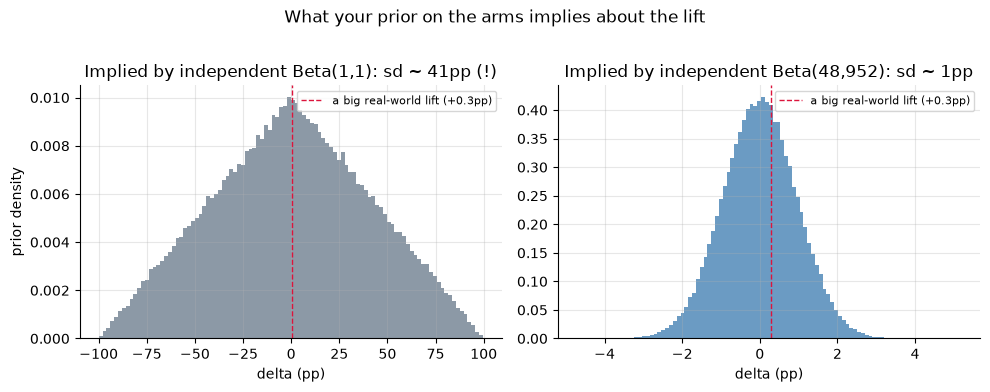

In [19]:
r3 = np.random.default_rng(3)
d_flat = r3.beta(1, 1, 200_000) - r3.beta(1, 1, 200_000)
d_hist = r3.beta(48, 952, 200_000) - r3.beta(48, 952, 200_000)
print(f"implied prior on delta:  flat priors sd = {d_flat.std() * 100:.1f}pp,  "
      f"P(|delta| > 5pp) = {(np.abs(d_flat) > 0.05).mean():.1%}")
print(f"                         history priors sd = {d_hist.std() * 100:.2f}pp")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(d_flat * 100, bins=100, density=True, color="slategray", alpha=0.8)
axes[0].set_title("Implied by independent Beta(1,1): sd ~ 41pp (!)")
axes[0].set_xlabel("delta (pp)")
axes[0].set_ylabel("prior density")
axes[1].hist(d_hist * 100, bins=100, density=True, color="steelblue", alpha=0.8)
axes[1].set_title("Implied by independent Beta(48,952): sd ~ 1pp")
axes[1].set_xlabel("delta (pp)")
for ax in axes:
    ax.axvline(0.3, color="crimson", ls="--", lw=1, label="a big real-world lift (+0.3pp)")
    ax.legend(fontsize=8)
fig.suptitle("What your prior on the arms implies about the lift", y=1.02)
plt.show()

The flat-prior analyst has unknowingly asserted that a ±40pp conversion swing is typical
and lifts beyond ±5pp have 90% prior probability — absurd for a mature product where
almost all experiments move metrics by well under 1pp. Two further consequences of
independent, identical arm priors: the prior says $P(B>A) = 50\%$ *exactly* — you cannot
encode "most experiments do nothing", which is a real, learnable fact; and it wastes the
strongest information you own. Priors on the *lift itself* — learned across your
experiment archive — fix both; that is partial pooling, the subject of
[03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb). At the ~40k scale of this
notebook the flat prior is harmless (Section 3's table proved it); at bandit or
early-stopping scale it is not.

## 11. Interview corner

**1. "Our Bayesian dashboard says P(B>A) = 97%; the old readout said p = 0.03. The PM
asks which is right." **
Both, but they answer different questions. $p = 0.03$: *if the arms were identical, data
this extreme happens 3% of the time* — a statement about the data under a hypothetical.
$P(B>A) = 97\%$: *given the data and a prior, B is better with 97% probability* — a
statement about the parameter, which is what the PM's mental model already is. With flat
priors and large n they're near-mechanical transforms of each other (our experiment:
one-sided p = 0.042 vs $1 - P(B>A) = 0.042$), so the real difference is the contract:
the p-value comes with error-rate control, the posterior with a prior you must defend.
Then redirect: neither is a decision — pair the probability with expected loss.

**2. "How do you pick a prior defensibly?"**
From history, with discounting: pool the metric's past values, match a Beta by mean and a
*deliberately shrunk* effective sample size (a few percent of the planned n, because the
past is a biased sample of the present). State it in pseudo-count language so
non-statisticians can audit it. Run the Section-3 sensitivity table — if the decision
flips across reasonable priors, the data hasn't decided; say so. Prefer priors on the
lift (hierarchical, from the experiment archive) over independent arm priors when you can.
And in high-stakes or adversarial settings, default to weak priors — a prior you can't
defend in a room is a liability, not information.

**3. "When does Bayesian A/B genuinely help?"**
(a) Low-traffic tests where defensible history exists — the only regime where priors add
real power. (b) When the *decision*, not the inference, is the product: expected-loss
stopping trades error control for 4–6× faster decisions with bounded regret — the right
trade for reversible product tweaks, the wrong one for a pricing migration. (c) Many-arm /
continuous optimization, where it becomes Thompson sampling. (d) Equivalence claims via
ROPE. (e) Communication. It does *not* help when stakeholders need error-rate guarantees,
when priors would be litigated, or at big-n where both frameworks give the same answer
anyway.

**4. "The PM wants to stop the moment P(B>A) hits 95%. Fine?"**
No — that's optional stopping on a moving statistic: ~22% of our simulated A/A tests
crossed 95% somewhere in 20 looks. Offer the legitimate alternatives: expected-loss
stopping with an explicit $\varepsilon$ (bounds regret, not false positives — make sure
that's the contract the PM wants) or sequential frequentist designs (mSPRT/GST) if error
rates are the contract.

**5. "Credible interval vs confidence interval — does it matter in practice?"**
Interpretation differs (probability about *this* interval vs coverage of the *procedure*),
numbers often don't: flat-prior Beta intervals match Wilson to ~4 decimals at our n. It
starts mattering with informative priors: right prior → narrower and better-covering;
wrong prior → confidently miscalibrated (we measured 75% actual coverage from a stale
prior claiming 95%). Say the phrase "the credible interval's honesty is exactly the
prior's honesty" and you're done.

**6. "How do you read out a revenue metric Bayesianly?"**
Two-part model: Beta-Binomial conversion × posterior for spend-given-conversion (Bayesian
bootstrap if you won't commit to a likelihood; lognormal/gamma in PyMC if you will).
Multiply draws, report the conversion/AOV/RPU decomposition, and set $\varepsilon$ in
dollars. Warn that revenue needs far more data — heavy-tailed spend among a few thousand
converters can leave a −4% AOV effect invisible, as in Section 8.

**7. "Your loss-rule shipped a variant that later proved worse. Did the method fail?"**
Not necessarily — it ships truly-worse arms by design when the expected cost is under
$\varepsilon$; across many decisions the realized regret averages below the threshold
(Section 6 measured it). The follow-ups that show seniority: was $\varepsilon$ set with
the business, is there a holdout to *detect* the miss, and does the org understand that
"shipped" never meant "proven better"?

## 12. Key takeaways

- Beta-Binomial conjugacy gives exact posteriors with arithmetic: prior = pseudo-counts,
  posterior mean = precision-weighted blend. This closed form powers every commercial
  Bayesian A/B tool — no MCMC required.
- Prior choice is an *auditable assumption*: state it in ESS units, discount history hard,
  and always show the sensitivity table on the decision quantity. Weak priors are
  decision-equivalent at normal experiment scale.
- Monte Carlo from two posteriors yields $P(B>A)$ and credible intervals for any derived
  quantity (absolute lift, relative lift, revenue). Validate MC against exact integrals
  when they exist.
- $P(B>A)$ is not a decision — it's scale-free. Expected loss (posterior regret) is the
  decision quantity; ship when it drops below an explicit threshold of caring
  $\varepsilon$.
- The $\varepsilon$-loss rule's operating characteristics, measured honestly: ~50% "false
  ships" under the null, 14–35% wrong ships under small negative effects — with realized
  regret pinned near $\varepsilon$ and decisions 4–6× faster than fixed-horizon testing.
  It bounds regret, not error rates. Sell the guarantee you actually have.
- Bayesian ≠ peek-proof: acting on "P(B>A) > 95%" inflates phantom winners to ~22% under
  the null with 20 looks. Coherent beliefs and controlled error rates are different
  properties.
- ROPE turns "flat result" into an actual conclusion — but certifying equivalence within
  ±0.1pp took 600k users/arm even with a true zero. Undecided ≠ equivalent.
- Zero-inflated revenue: factor into conversion × spend, model each, multiply draws.
  Expect revenue to stay uncertain long after conversion is settled.
- Credible intervals numerically match CIs under flat priors; informative priors buy
  sharper inference *iff* they're right — a stale prior claiming 95% covered the truth
  75% of the time.

## 13. Exercises

**Exercise 1.** The threshold of caring $\varepsilon$ is a knob. Re-run the Section 6
operating-characteristics simulation for $\varepsilon \in \{0.01, 0.04, 0.10\}$pp under
true effects −0.1pp and +0.3pp. How do speed, ship rates, and realized regret trade off?
What silently breaks when $\varepsilon$ is far below what the traffic budget can resolve?

**Exercise 2.** For integer Beta parameters there is a closed form (popularized by Evan
Miller): $P(p_B > p_A) = \sum_{i=0}^{\alpha_B - 1}
\frac{B(\alpha_A + i, \beta_A + \beta_B)}{(\beta_B + i)\, B(1 + i, \beta_B)\,
B(\alpha_A, \beta_A)}$. Implement it stably in log-space and check it against the grid
integral and the Monte Carlo estimate for the main experiment.

**Exercise 3.** Derive the per-arm sample size needed for an A/A-style comparison to
conclude practical equivalence (95% interval inside a ±w ROPE) with 80% probability,
using the normal approximation. Evaluate it for w = 0.1pp at baseline 4.8%, verify by
simulation, and check how often the notebook's 40k/arm design could ever certify
equivalence.

In [20]:
# --- Solution to Exercise 1 ---
rows = []
for j, eps in enumerate([1e-4, 4e-4, 1e-3]):
    for k, d in enumerate([-0.001, 0.003]):
        res = run_decision_sims(d, seed=301 + 10 * j + k, eps=eps)
        rows.append({"eps (pp)": eps * 100, "true delta (pp)": d * 100,
                     "ship B (%)": 100 * res["ship_B"].mean(),
                     "mean n/arm": res["n_stop"].mean(),
                     "mean regret (pp)": 100 * res["regret"].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("""
Reading: eps is a speed/regret dial. Tight eps (0.01pp) is slow (mean ~16-23k/arm) and
rarely ships a truly-worse arm; loose eps (0.10pp) decides in ~3.5-3.8k users/arm but
wrong-ships the -0.1pp loser 41% of the time. The break: at eps=0.01pp the threshold is
rarely reachable within 40k/arm, so most "decisions" are forced horizon calls -- and those
carry NO expected-loss guarantee (regret 0.029pp, 3x eps). Choose eps jointly with the
traffic budget, or the guarantee quietly evaporates.""")

 eps (pp)  true delta (pp)  ship B (%)  mean n/arm  mean regret (pp)
     0.01             -0.1       28.55     22914.0             0.029
     0.01              0.3       94.25     16120.0             0.017
     0.04             -0.1       34.00      8628.0             0.034
     0.04              0.3       84.35      7171.0             0.047
     0.10             -0.1       40.60      3802.0             0.041
     0.10              0.3       74.65      3550.0             0.076

Reading: eps is a speed/regret dial. Tight eps (0.01pp) is slow (mean ~16-23k/arm) and
rarely ships a truly-worse arm; loose eps (0.10pp) decides in ~3.5-3.8k users/arm but
wrong-ships the -0.1pp loser 41% of the time. The break: at eps=0.01pp the threshold is
rarely reachable within 40k/arm, so most "decisions" are forced horizon calls -- and those
carry NO expected-loss guarantee (regret 0.029pp, 3x eps). Choose eps jointly with the
traffic budget, or the guarantee quietly evaporates.


In [21]:
# --- Solution to Exercise 2 ---
def prob_B_beats_A_closed(a_A, b_A, a_B, b_B):
    """Exact P(p_B > p_A) for integer a_B, computed in log-space for stability."""
    i = np.arange(int(a_B))
    log_terms = (betaln(a_A + i, b_A + b_B) - np.log(b_B + i)
                 - betaln(1 + i, b_B) - betaln(a_A, b_A))
    return np.exp(log_terms).sum()


closed = prob_B_beats_A_closed(a_post_A, b_post_A, a_post_B, b_post_B)
mc_se = np.sqrt(closed * (1 - closed) / N_MC)
print(f"closed form:   {closed:.6f}")
print(f"grid integral: {p_sup_exact:.6f}   (agree to {abs(closed - p_sup_exact):.1e})")
print(f"Monte Carlo:   {p_sup_mc:.6f}   ({abs(p_sup_mc - closed) / mc_se:.1f} MC standard errors away)")

closed form:   0.957860
grid integral: 0.957860   (agree to 1.4e-10)
Monte Carlo:   0.957534   (1.1 MC standard errors away)


In [22]:
# --- Solution to Exercise 3 ---
# Equivalence needs the whole 95% interval inside (-w, w): |m_hat| + 1.96*se < w.
# With m_hat ~ N(0, se^2) under a true null, P(conclude) = P(|m_hat| < w - 1.96*se).
# Requiring this to be 80% (two-sided containment) means w - 1.96*se >= z_0.90 * se,
# i.e. se <= w / (z_.975 + z_.90)  ->  n >= 2 p (1-p) ((z_.975 + z_.90) / w)^2.
p0, w = 0.048, 0.001
z975, z90 = stats.norm.ppf(0.975), stats.norm.ppf(0.90)
n_req = int(np.ceil(2 * p0 * (1 - p0) * ((z975 + z90) / w) ** 2))
print(f"required n/arm for 80% probability of certifying equivalence: {n_req:,}")

r_ex = np.random.default_rng(11)
for n_ in (n_req, 40_000):
    x_a = r_ex.binomial(n_, p0, 2000)
    x_b = r_ex.binomial(n_, p0, 2000)
    pa_h, pb_h = x_a / n_, x_b / n_
    m_h = pb_h - pa_h
    se = np.sqrt(pa_h * (1 - pa_h) / n_ + pb_h * (1 - pb_h) / n_)
    inside = ((m_h - z975 * se > -w) & (m_h + z975 * se < w)).mean()
    print(f"  simulated P(conclude equivalence) at n={n_:,}/arm: {inside:.1%}")
print("""
~960k users/arm -- 24x the notebook's design -- and at 40k/arm the probability is exactly
zero: the interval is wider than the ROPE, so equivalence is unprovable at that n no
matter what the data say. Superiority tests that come back 'flat' are not equivalence
evidence; they are underpowered silence.""")

required n/arm for 80% probability of certifying equivalence: 960,295
  simulated P(conclude equivalence) at n=960,295/arm: 78.9%
  simulated P(conclude equivalence) at n=40,000/arm: 0.0%

~960k users/arm -- 24x the notebook's design -- and at 40k/arm the probability is exactly
zero: the interval is wider than the ROPE, so equivalence is unprovable at that n no
matter what the data say. Superiority tests that come back 'flat' are not equivalence
evidence; they are underpowered silence.
